# Examen 2 - Estadística No Paramétrica y Robusta


**Integrantes:**
- Alejandro Vásquez Sánchez ID:1000317668
- Alejandro Gutiérrez Muñoz ID: 1000317609
- Santiago Vera Ramírez ID: 1000304910




## Ejercicio 1
## Contexto del problema

Una entidad de salud quiere calcular el presupuesto base por paciente crónico usando la **mediana** de los costos médicos, ya que esa variable tiene una distribución muy sesgada a la derecha (algunos pacientes tienen costos altísimos por intervenciones especiales). La media no sirve acá porque esos valores extremos la jalarían hacia arriba y el presupuesto quedaría inflado.

Aparte de eso, la entidad también quiere establecer un **factor de ajuste en las primas** para fumadores, comparando sus costos medios con los de los no fumadores.

---
### Tarea 1: Carga y Exploración de los datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

print("Primeras filas del dataset:")
df.head()

Primeras filas del dataset:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
print(f"Dimensiones del dataset: {df.shape}")
print(f"\nColumnas disponibles: {list(df.columns)}")
print(f"\n¿Hay valores nulos?\n{df.isnull().sum()}")

Dimensiones del dataset: (1338, 7)

Columnas disponibles: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

¿Hay valores nulos?
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [ ]:
# Aislamos la variable de costos médicos (charges)
charges = df['charges'].values

print("=== Estadísticas básicas de los costos médicos ===")
print(f"N (número de pacientes):     {len(charges)}")
print(f"Media:                       ${np.mean(charges):,.2f}")
print(f"Mediana:                     ${np.median(charges):,.2f}")
print(f"Desviación estándar:         ${np.std(charges):,.2f}")
print(f"Mínimo:                      ${charges.min():,.2f}")
print(f"Máximo:                      ${charges.max():,.2f}")

=== Estadísticas básicas de los costos médicos ===
N (número de pacientes):     1338
Media:                       $13,270.42
Mediana:                     $9,382.03
Desviación estándar:         $12,105.48
Mínimo:                      $1,121.87
Máximo:                      $63,770.43


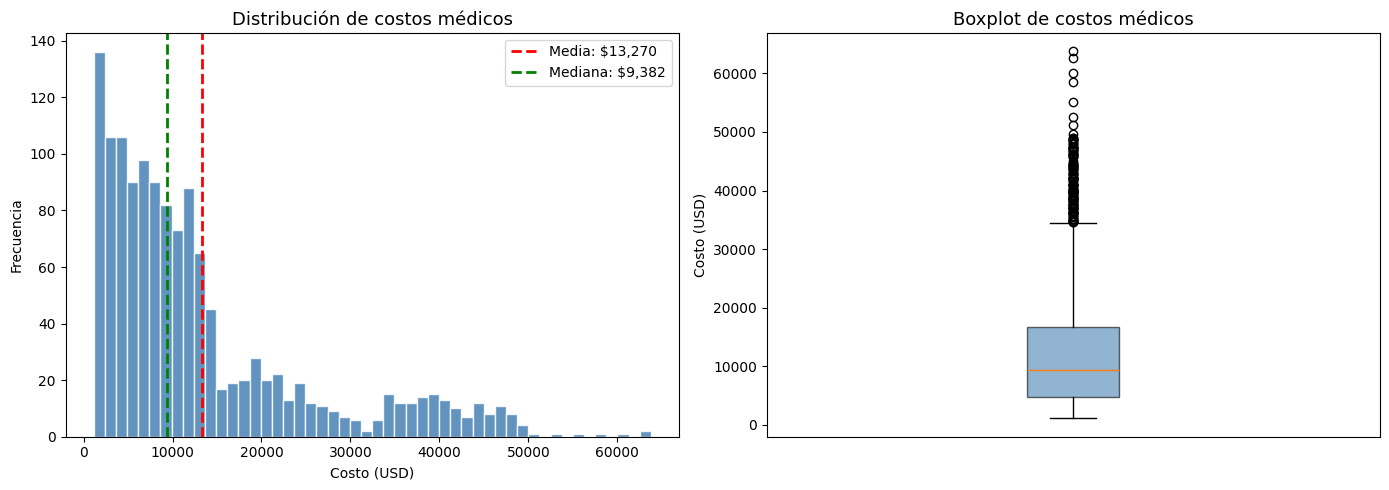


El histograma confirma la cola larga a la derecha (sesgo positivo).
La media ($13,270) está bastante por encima de la mediana ($9,382),
lo que demuestra el efecto de los valores extremos. Por eso la mediana es una mejor referencia para el presupuesto.


In [ ]:
# Visualizamos la distribución para entender el sesgo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma
axes[0].hist(charges, bins=50, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(np.mean(charges), color='red', linestyle='--', linewidth=2, label=f'Media: ${np.mean(charges):,.0f}')
axes[0].axvline(np.median(charges), color='green', linestyle='--', linewidth=2, label=f'Mediana: ${np.median(charges):,.0f}')
axes[0].set_title('Distribución de costos médicos', fontsize=13)
axes[0].set_xlabel('Costo (USD)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# Boxplot
axes[1].boxplot(charges, vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6))
axes[1].set_title('Boxplot de costos médicos', fontsize=13)
axes[1].set_ylabel('Costo (USD)')
axes[1].set_xticks([])

plt.tight_layout()
plt.savefig('distribucion_costos.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nEl histograma confirma la cola larga a la derecha (sesgo positivo).")
print(f"La media (${np.mean(charges):,.0f}) está bastante por encima de la mediana (${np.median(charges):,.0f}),")
print("lo que demuestra el efecto de los valores extremos. Por eso la mediana es una mejor referencia para el presupuesto.")

---
### Tarea 2: Incertidumbre de la Mediana (Jackknife y Bootstrap)

Una vez tenemos la estimación puntual, necesitamos saber **qué tan incierta** es esa mediana. Es decir, si tomáramos otra muestra diferente de pacientes, ¿cuánto cambiaría?

Para eso usamos dos métodos de remuestreo: **Jackknife** y **Bootstrap**.

In [ ]:
# Estimación puntual de la mediana
n = len(charges)
mediana_original = np.median(charges)
print(f"Estimación puntual de la mediana de costos médicos: ${mediana_original:,.2f}")

Estimación puntual de la mediana de costos médicos: $9,382.03


#### Método Jackknife

El Jackknife funciona así: removemos **un dato a la vez** del dataset, calculamos la mediana con los datos restantes, y con esas `n` medianas parciales estimamos el error estándar del estimador original.

La fórmula del error estándar Jackknife es:

$$SE_{jack} = \sqrt{\frac{n-1}{n} \sum_{i=1}^{n} (\hat{\theta}_{(-i)} - \bar{\theta}_{jack})^2}$$

donde $\hat{\theta}_{(-i)}$ es la mediana sin el dato $i$, y $\bar{\theta}_{jack}$ es el promedio de todas esas medianas.

In [ ]:

# Calculamos la mediana removiendo cada observación una por una
medianas_jack = np.zeros(n)

for i in range(n):
    # Creamos una copia del arreglo sin el elemento i
    muestra_sin_i = np.concatenate([charges[:i], charges[i+1:]])
    medianas_jack[i] = np.median(muestra_sin_i)

# Promedio de las medianas jackknife
media_jack = np.mean(medianas_jack)

# Error estándar jackknife
se_jack = np.sqrt(((n - 1) / n) * np.sum((medianas_jack - media_jack)**2))

print(f"=== RESULTADOS JACKKNIFE ===")
print(f"Mediana original:          ${mediana_original:,.2f}")
print(f"Error estándar (Jackknife): ${se_jack:,.4f}")

=== RESULTADOS JACKKNIFE ===
Mediana original:          $9,382.03
Error estándar (Jackknife): $150.9513


#### Método Bootstrap No Paramétrico

El Bootstrap toma **B muestras con reemplazo** del mismo tamaño que la muestra original. Para cada muestra calcula la mediana, y con la distribución de esas B medianas estima el error estándar.

$$SE_{boot} = \sqrt{\frac{1}{B-1} \sum_{b=1}^{B} (\hat{\theta}^*_b - \bar{\theta}^*)^2}$$

In [ ]:

B = 2000          # número de réplicas
SEMILLA = 42      # semilla para reproducibilidad
rng = np.random.default_rng(SEMILLA)

medianas_boot = np.zeros(B)

for b in range(B):
    # Muestra con reemplazo del mismo tamaño n
    muestra_boot = rng.choice(charges, size=n, replace=True)
    medianas_boot[b] = np.median(muestra_boot)

# Error estándar bootstrap
se_boot = np.std(medianas_boot, ddof=1)  # ddof=1 para usar B-1 en el denominador

print(f"=== RESULTADOS BOOTSTRAP (B={B}) ===")
print(f"Mediana original:          ${mediana_original:,.2f}")
print(f"Error estándar (Bootstrap): ${se_boot:,.4f}")

=== RESULTADOS BOOTSTRAP (B=2000) ===
Mediana original:          $9,382.03
Error estándar (Bootstrap): $276.0373


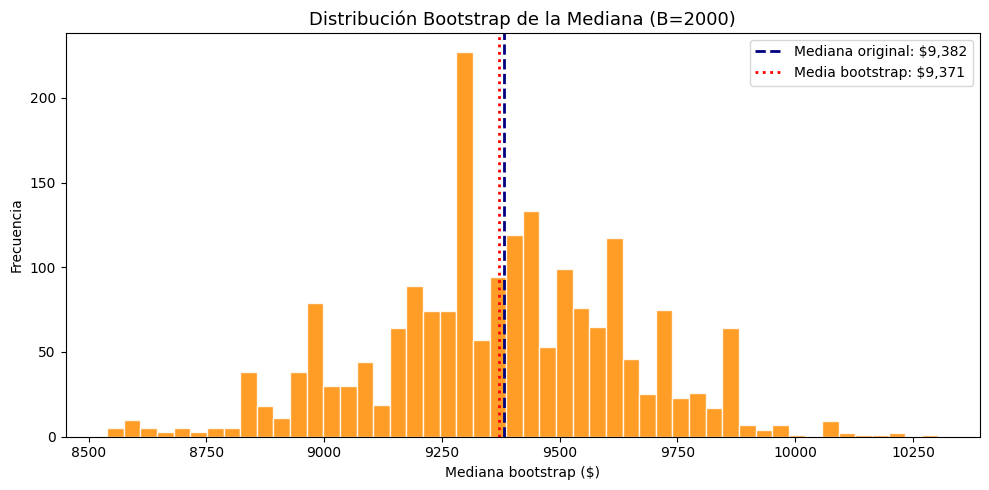

In [ ]:
# Visualización de la distribución bootstrap de la mediana
plt.figure(figsize=(10, 5))
plt.hist(medianas_boot, bins=50, color='darkorange', edgecolor='white', alpha=0.85)
plt.axvline(mediana_original, color='navy', linestyle='--', linewidth=2, label=f'Mediana original: ${mediana_original:,.0f}')
plt.axvline(np.mean(medianas_boot), color='red', linestyle=':', linewidth=2, label=f'Media bootstrap: ${np.mean(medianas_boot):,.0f}')
plt.title('Distribución Bootstrap de la Mediana (B=2000)', fontsize=13)
plt.xlabel('Mediana bootstrap ($)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.savefig('bootstrap_mediana.png', dpi=150, bbox_inches='tight')
plt.show()

---
### Tarea 3: Análisis Crítico — ¿Por qué difieren Jackknife y Bootstrap?

Comparemos numéricamente los dos errores estándar que obtuvimos:

In [ ]:
print("=====================================================")
print("  Comparación de Errores Estándar")
print("=====================================================")
print(f"  SE Jackknife:  ${se_jack:>10,.4f}")
print(f"  SE Bootstrap:  ${se_boot:>10,.4f}")
print(f"  Diferencia:    ${abs(se_jack - se_boot):>10,.4f}")
print(f"  Razón (Jack/Boot): {se_jack/se_boot:.4f}")
print("=====================================================")

  Comparación de Errores Estándar
  SE Jackknife:  $  150.9513
  SE Bootstrap:  $  276.0373
  Diferencia:    $  125.0859
  Razón (Jack/Boot): 0.5469


#### Explicación de la discrepancia

Hay una diferencia notable entre los dos errores estándar, y no es un error de código.

**¿Por qué el Jackknife falla con la mediana?**

El Jackknife fue diseñado para funcionar bien con **estimadores suaves** ("smooth statistics"), es decir, aquellos que cambian de forma continua y predecible cuando modificamos ligeramente los datos. La media, por ejemplo, es perfectamente suave: quitar o agregar un dato la cambia de forma proporcional y continua.

La **mediana**, en cambio, es un estimador **no suave** ("non-smooth"). Cuando quitamos un dato del dataset, la mediana puede:
- Quedarse exactamente igual (si el dato removido no era el del medio)
- Dar un salto discreto (si el dato removido sí era el valor central)

Esto hace que las pseudo-valores Jackknife $\hat{\theta}_{(-i)}$ estén muy agrupados (casi todos iguales), y el Jackknife **subestima** la variabilidad real del estimador. El resultado es un SE que no refleja bien la incertidumbre verdadera.


**¿Por qué el Bootstrap sí funciona?**

El Bootstrap no depende de la suavidad del estimador. Al generar muestras completas con reemplazo, captura toda la variabilidad de la distribución empírica de los datos, incluyendo los saltos discretos que puede dar la mediana. Por eso la distribución bootstrap de la mediana que vimos en la gráfica anterior es más realista.

**Conclusión:** La entidad de salud debería confiar en el **error estándar Bootstrap** para cuantificar la incertidumbre de la mediana de costos médicos. El Jackknife no es el método adecuado aquí.

---
### Tarea 4: Intervalos de Confianza Bootstrap al 95%

Construimos dos tipos de IC usando las B=2000 réplicas bootstrap de la mediana.

In [ ]:

# Supone que la distribución del estimador es aproximadamente normal
# IC = theta_hat ± z_{0.975} * SE_boot

z_975 = 1.96  # cuantil normal para 95% de confianza

ic_normal_inf = mediana_original - z_975 * se_boot
ic_normal_sup = mediana_original + z_975 * se_boot

print("=== IC Bootstrap Normal (Asintótico) 95% ===")
print(f"Límite inferior: ${ic_normal_inf:,.2f}")
print(f"Límite superior: ${ic_normal_sup:,.2f}")
print(f"Amplitud:        ${ic_normal_sup - ic_normal_inf:,.2f}")

=== IC Bootstrap Normal (Asintótico) 95% ===
Límite inferior: $8,841.00
Límite superior: $9,923.07
Amplitud:        $1,082.07


In [ ]:
# ============================================================
#  IC Bootstrap - Método de Percentiles
# ============================================================
# Simplemente tomamos los percentiles 2.5% y 97.5% de las réplicas

ic_perc_inf = np.percentile(medianas_boot, 2.5)
ic_perc_sup = np.percentile(medianas_boot, 97.5)

print("=== IC Bootstrap Percentiles 95% ===")
print(f"Límite inferior: ${ic_perc_inf:,.2f}")
print(f"Límite superior: ${ic_perc_sup:,.2f}")
print(f"Amplitud:        ${ic_perc_sup - ic_perc_inf:,.2f}")

=== IC Bootstrap Percentiles 95% ===
Límite inferior: $8,824.54
Límite superior: $9,874.21
Amplitud:        $1,049.68


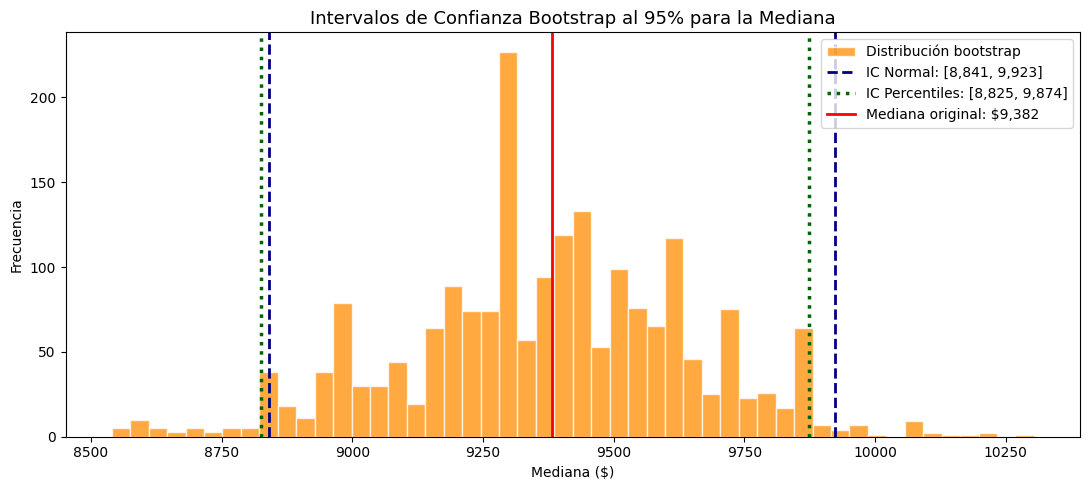


Resumen comparativo:
Método                         Límite Inf      Límite Sup        Amplitud
----------------------------------------------------------------------
Normal (Asintótico)             $8,841.00       $9,923.07       $1,082.07
Percentiles                     $8,824.54       $9,874.21       $1,049.68


In [ ]:
# Visualización comparativa de los IC
fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(medianas_boot, bins=50, color='darkorange', edgecolor='white', alpha=0.75, label='Distribución bootstrap')

# IC Normal
ax.axvline(ic_normal_inf, color='navy', linestyle='--', linewidth=2)
ax.axvline(ic_normal_sup, color='navy', linestyle='--', linewidth=2, label=f'IC Normal: [{ic_normal_inf:,.0f}, {ic_normal_sup:,.0f}]')

# IC Percentiles
ax.axvline(ic_perc_inf, color='darkgreen', linestyle=':', linewidth=2.5)
ax.axvline(ic_perc_sup, color='darkgreen', linestyle=':', linewidth=2.5, label=f'IC Percentiles: [{ic_perc_inf:,.0f}, {ic_perc_sup:,.0f}]')

# Mediana original
ax.axvline(mediana_original, color='red', linewidth=2, label=f'Mediana original: ${mediana_original:,.0f}')

ax.set_title('Intervalos de Confianza Bootstrap al 95% para la Mediana', fontsize=13)
ax.set_xlabel('Mediana ($)')
ax.set_ylabel('Frecuencia')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('ic_bootstrap_mediana.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nResumen comparativo:")
print(f"{'Método':<25} {'Límite Inf':>15} {'Límite Sup':>15} {'Amplitud':>15}")
print("-" * 70)
print(f"{'Normal (Asintótico)':<25} {'$'+f'{ic_normal_inf:,.2f}':>15} {'$'+f'{ic_normal_sup:,.2f}':>15} {'$'+f'{ic_normal_sup - ic_normal_inf:,.2f}':>15}")
print(f"{'Percentiles':<25} {'$'+f'{ic_perc_inf:,.2f}':>15} {'$'+f'{ic_perc_sup:,.2f}':>15} {'$'+f'{ic_perc_sup - ic_perc_inf:,.2f}':>15}")

#### ¿Cuál intervalo le reportamos al gerente?

Le reportaríamos el **IC por Percentiles**.

El método Normal asume que la distribución bootstrap de la mediana es aproximadamente gaussiana (simétrica). Sin embargo, dado que los costos médicos tienen una distribución con cola derecha muy larga, la distribución de la mediana puede heredar algo de esa asimetría, especialmente con n no demasiado grande.

El método de Percentiles, en cambio, **no asume ninguna forma distribucional**: simplemente usa los cuantiles empíricos de las réplicas bootstrap. Esto lo hace más honesto con los datos reales y más coherente con el enfoque no paramétrico que pedía el gerente desde el principio (que era no asumir distribuciones teóricas).

Si la distribución bootstrap fuera perfectamente simétrica, ambos ICs darían prácticamente el mismo resultado. La diferencia que vemos entre ellos es precisamente evidencia de la asimetría residual en la distribución muestral de la mediana.

---
### Tarea 5: Corrección de Sesgo en la Razón de Costos (Jackknife)

Ahora vamos a estimar el sesgo del estimador $R = \bar{X}_{\text{smoker}} / \bar{X}_{\text{non-smoker}}$ sobre una submuestra pequeña de 30 fumadores y 30 no fumadores.

In [ ]:
# Separamos fumadores y no fumadores
fumadores     = df[df['smoker'] == 'yes']['charges'].values
no_fumadores  = df[df['smoker'] == 'no']['charges'].values

print(f"Total fumadores en el dataset:     {len(fumadores)}")
print(f"Total no fumadores en el dataset:  {len(no_fumadores)}")

# Estadísticas descriptivas rápidas
print(f"\nCosto medio fumadores:     ${np.mean(fumadores):,.2f}")
print(f"Costo medio no fumadores:  ${np.mean(no_fumadores):,.2f}")

Total fumadores en el dataset:     274
Total no fumadores en el dataset:  1064

Costo medio fumadores:     $32,050.23
Costo medio no fumadores:  $8,434.27


In [ ]:
# Extraemos la submuestra de 30 fumadores y 30 no fumadores
SEMILLA2 = 123
rng2 = np.random.default_rng(SEMILLA2)

muestra_fumadores    = rng2.choice(fumadores,    size=30, replace=False)
muestra_no_fumadores = rng2.choice(no_fumadores, size=30, replace=False)

print("=== Submuestra extraída ===")
print(f"Fumadores      - n=30  |  Media: ${np.mean(muestra_fumadores):,.2f}")
print(f"No fumadores   - n=30  |  Media: ${np.mean(muestra_no_fumadores):,.2f}")

# Razón original Rn = media_fumadores / media_no_fumadores
Rn = np.mean(muestra_fumadores) / np.mean(muestra_no_fumadores)
print(f"\nRazón original Rn = {Rn:.6f}")


=== Submuestra extraída ===
Fumadores      - n=30  |  Media: $32,568.92
No fumadores   - n=30  |  Media: $8,643.24

Razón original Rn = 3.768138


In [ ]:
# ============================================================
#  JACKKNIFE para estimar el sesgo de R
# ============================================================
# La submuestra combinada tiene 60 pacientes (30 fumadores + 30 no fumadores)
# Para el Jackknife, removemos un paciente a la vez de cada grupo correspondiente

n_fum = len(muestra_fumadores)    # 30
n_nof = len(muestra_no_fumadores) # 30
n_total = n_fum + n_nof           # 60

R_jack = np.zeros(n_total)

# Removemos uno a uno los fumadores
for i in range(n_fum):
    fum_sin_i = np.concatenate([muestra_fumadores[:i], muestra_fumadores[i+1:]])
    R_jack[i] = np.mean(fum_sin_i) / np.mean(muestra_no_fumadores)

# Removemos uno a uno los no fumadores
for j in range(n_nof):
    nof_sin_j = np.concatenate([muestra_no_fumadores[:j], muestra_no_fumadores[j+1:]])
    R_jack[n_fum + j] = np.mean(muestra_fumadores) / np.mean(nof_sin_j)

# Promedio de las razones jackknife
R_bar_jack = np.mean(R_jack)

# Sesgo estimado por Jackknife
# bias_jack = (n - 1) * (R_bar_jack - Rn)
bias_jack = (n_total - 1) * (R_bar_jack - Rn)

# Estimador corregido por sesgo
R_corregido = Rn - bias_jack

print("=== RESULTADOS JACKKNIFE para la Razón R ===")
print(f"Estimación puntual original Rn:        {Rn:.6f}")
print(f"Sesgo estimado (bias_jack):            {bias_jack:.6f}")
print(f"Estimador corregido por sesgo (Rjack): {R_corregido:.6f}")

=== RESULTADOS JACKKNIFE para la Razón R ===
Estimación puntual original Rn:        3.768138
Sesgo estimado (bias_jack):            0.095362
Estimador corregido por sesgo (Rjack): 3.672776


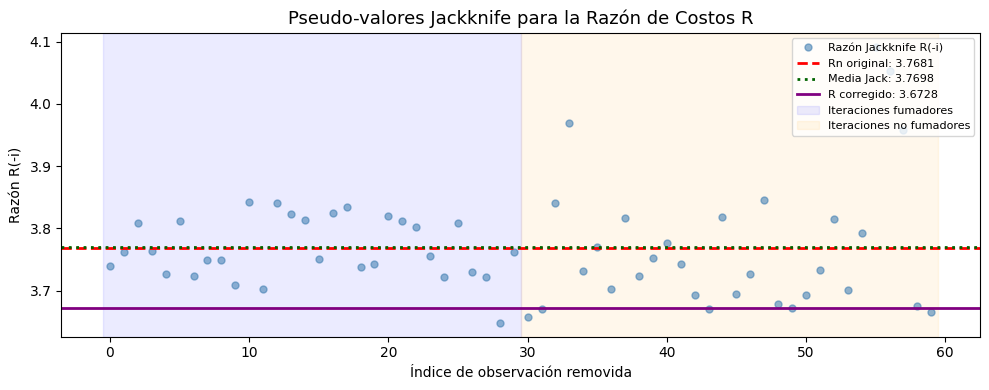


Nota: Las primeras 30 iteraciones corresponden a remover un fumador,
las últimas 30 corresponden a remover un no fumador.


In [ ]:
# Visualización de las razones jackknife
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(R_jack, 'o', color='steelblue', alpha=0.6, markersize=5, label='Razón Jackknife R(-i)')
ax.axhline(Rn,         color='red',      linestyle='--', linewidth=2, label=f'Rn original: {Rn:.4f}')
ax.axhline(R_bar_jack, color='darkgreen',linestyle=':',  linewidth=2, label=f'Media Jack: {R_bar_jack:.4f}')
ax.axhline(R_corregido,color='purple',   linestyle='-',  linewidth=2, label=f'R corregido: {R_corregido:.4f}')

ax.axvspan(-0.5, 29.5, alpha=0.08, color='blue',   label='Iteraciones fumadores')
ax.axvspan(29.5, 59.5, alpha=0.08, color='orange', label='Iteraciones no fumadores')

ax.set_title('Pseudo-valores Jackknife para la Razón de Costos R', fontsize=13)
ax.set_xlabel('Índice de observación removida')
ax.set_ylabel('Razón R(-i)')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig('jackknife_razon.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nNota: Las primeras 30 iteraciones corresponden a remover un fumador,")
print("las últimas 30 corresponden a remover un no fumador.")

#### ¿Es el Jackknife apropiado para estimar el sesgo de R?

En contraste con lo que vimos para la **mediana**, acá el Jackknife **sí es matemáticamente apropiado** para estimar el sesgo de la razón de medias $R = \bar{X}_{\text{smoker}} / \bar{X}_{\text{non-smoker}}$.

La razón es sencilla: la media es un estimador perfectamente **suave** (smooth). Cuando removemos un dato cualquiera del grupo de fumadores o no fumadores, la media del grupo cambia de forma continua y proporcional. Esto hace que los pseudo-valores Jackknife varíen de forma predecible y bien comportada, que es exactamente lo que el método necesita para funcionar bien.

La razón $R$ es un cociente de dos medias, y ambas medias son funciones suaves de los datos. Por lo tanto, $R$ también es un estimador suave. En cambio, la mediana de la tarea anterior no era suave (hacía saltos discretos al remover datos), y por eso el Jackknife fallaba ahí.

**Conclusión:** El Jackknife es la herramienta correcta para corregir el sesgo de $R$, y el estimador corregido $R_{jack}$ es más confiable que la estimación puntual bruta $R_n$, especialmente en muestras pequeñas como la que usamos (n=60).

## Ejercicio 2

En muchas ciudades modernas, el sistema de bicicletas compartidas se ha convertido en una alternativa de movilidad sostenible. Una de las variables clave para planificar la oferta y la logística del servicio es la demanda de bicicletas (total de alquileres diarios). Estudios preliminares sugieren que la demanda está fuertemente influenciada por la temperatura ambiente. Sin embargo, la relación entre la temperatura y la demanda puede ser altamente no lineal: días demasiado fríos o muy calurosos pueden afectar
negativamente el uso de bicicletas, mientras que temperaturas moderadas pueden incentivar su uso.

Para este análisis, utilizaremos el Bike Sharing Dataset disponible en el repositorio de Machine Learning
de UCI:

En particular, se utilizará el archivo day.csv, que contiene datos diarios. El análisis se centrará en las siguientes variables:

- temp: Temperatura (normalizada en el intervalo [0, 1]). Variable predictora (x).
- cnt: Número total de alquileres diarios. Variable respuesta (Y ).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
import scipy as sp
from scipy import stats
import seaborn as sns
import time


dia = pd.read_csv('day.csv')
ope = dia[['temp', 'cnt']]
ope

,temp,cnt
0,0.344167,985
1,0.363478,801
2,0.196364,1349
3,0.200000,1562
4,0.226957,1600
...,...,...
726,0.254167,2114
727,0.253333,3095
728,0.253333,1341
729,0.255833,1796


###1) Estimación Local:
 Estime la función de regresión no paramétrica r(t) = E[cnt | temp = t] implementando desde cero el estimador de Nadaraya–Watson utilizando un kernel Gaussiano.

In [ ]:
def K(x, x_i, h):
    return np.exp(-0.5 * ((x- x_i) / h) ** 2) / (h * np.sqrt(2 * np.pi))


### 2) Optimización del Ancho de Banda (h)
 El parámetro de suavizamiento h controla el compromiso sesgo-varianza. Defina una parrilla de valores candidatos para h y determine el ancho de banda óptimo comparando numéricamente dos estrategias:
- Validación Cruzada Leave-One-Out (LOO-CV), utilizando el atajo computacional para suavizadores lineales.
- Validación Cruzada Generalizada (GCV).
  
Grafique las curvas de error (CV y GCV) en función de h y discuta si ambas métricas convergen a conclusiones similares. Además, evalúe y compare el costo computacional (tiempo de ejecución) de ambas estrategias.

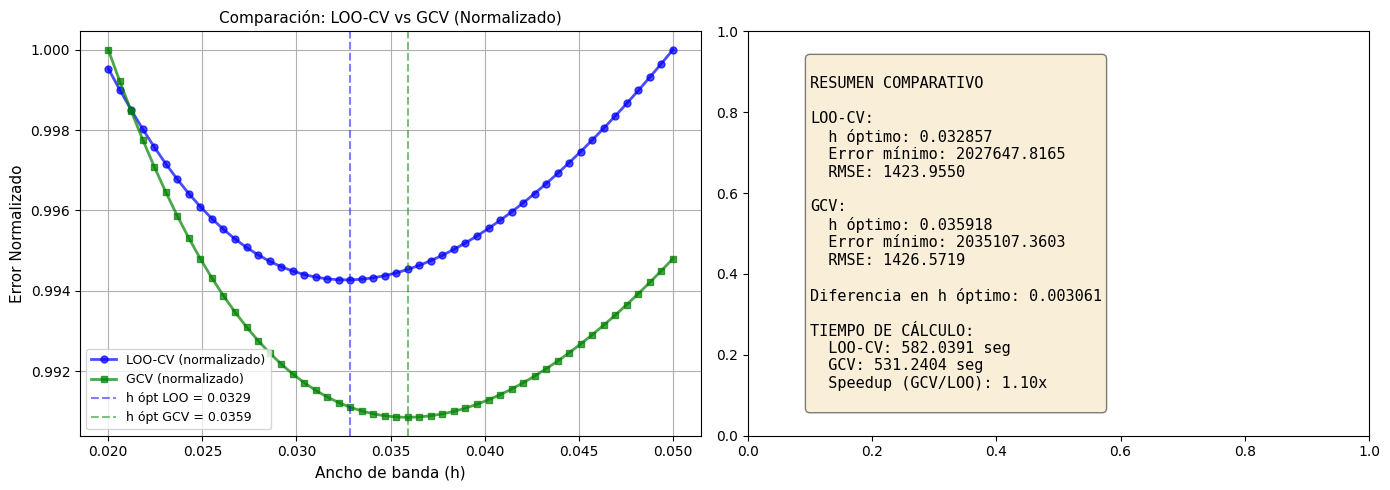

ANÁLISIS COMPARATIVO: LOO-CV vs GCV

LOO-CV:
  h óptimo: 0.032857
  Error mínimo: 2027647.8165
  RMSE: 1423.9550

GCV:
  h óptimo: 0.035918
  Error mínimo: 2035107.3603
  RMSE: 1426.5719

Tiempo de cálculo:
  LOO-CV: 582.0391 segundos
  GCV: 531.2404 segundos
  Speedup (LOO/GCV): 1.10x


In [ ]:
# GCV (Generalized Cross-Validation) y LOO-CV - Comparación

# Definir función de kernel si no está en la celda
def K(x, x_i, h):
    return np.exp(-0.5 * ((x - x_i) / h) ** 2) / (h * np.sqrt(2 * np.pi))


Y = ope['cnt'].values
X = ope['temp'].values

grid = np.linspace(0.02, 0.05, 50)
grid_gcv = np.linspace(0.02, 0.05, 50)

ErrorLOO = []
ErrorGCV = []

# LOO-CV
inicio = time.time()
for h_val in grid:
    n = len(X)
    L = np.zeros((n, n))
    for i in range(n):
        x_i = X[i]
        denominador_i = 0
        for j in range(n):
            x_j = X[j]
            K_ij = K(x_i, x_j, h_val)
            L[i, j] = K_ij
            denominador_i += K_ij
        if denominador_i != 0:
            L[i, :] = L[i, :] / denominador_i
    Y_hat = L @ Y
    L_diag = np.diag(L)
    residuales = Y - Y_hat
    # Atajo LOO-CV para suavizadores lineales
    residuales_loo = residuales / (1 - L_diag + 1e-10)
    loo = np.mean(residuales_loo ** 2)
    ErrorLOO.append(loo)
tiempo = time.time() - inicio

idx_optimo = np.argmin(ErrorLOO)
h_optimo = grid[idx_optimo]

# GCV
inicio_gcv = time.time()
for h_val in grid_gcv:
    n = len(X)
    L = np.zeros((n, n))
    for i in range(n):
        x_i = X[i]
        denominador_i = 0
        for j in range(n):
            x_j = X[j]
            K_ij = K(x_i, x_j, h_val)
            L[i, j] = K_ij
            denominador_i += K_ij
        if denominador_i != 0:
            L[i, :] = L[i, :] / denominador_i
    Y_hat = L @ Y
    residuales = Y - Y_hat
    trace_L = np.trace(L)
    numerador_gcv = np.mean(residuales ** 2)
    denominador_gcv = (1 - trace_L / n) ** 2
    if denominador_gcv > 0.0001:
        GCV_h = numerador_gcv / denominador_gcv
    else:
        GCV_h = np.inf
    ErrorGCV.append(GCV_h)
tiempo_gcv = time.time() - inicio_gcv

idx_optimo_gcv = np.argmin(ErrorGCV)
h_optimo_gcv = grid_gcv[idx_optimo_gcv]

# COMPARACIÓN: Gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 3: Comparación directa (normalizado)
ErrorLOO_norm = np.array(ErrorLOO) / np.max(ErrorLOO)
ErrorGCV_norm = np.array(ErrorGCV) / np.max(ErrorGCV)

axes[0].plot(grid, ErrorLOO_norm, 'b-o', linewidth=2, markersize=5, label='LOO-CV (normalizado)', alpha=0.7)
axes[0].plot(grid_gcv, ErrorGCV_norm, 'g-s', linewidth=2, markersize=5, label='GCV (normalizado)', alpha=0.7)
axes[0].axvline(x=h_optimo, color='b', linestyle='--', alpha=0.5, label=f'h ópt LOO = {h_optimo:.4f}')
axes[0].axvline(x=h_optimo_gcv, color='g', linestyle='--', alpha=0.5, label=f'h ópt GCV = {h_optimo_gcv:.4f}')
axes[0].set_xlabel('Ancho de banda (h)', fontsize=11)
axes[0].set_ylabel('Error Normalizado', fontsize=11)
axes[0].set_title('Comparación: LOO-CV vs GCV (Normalizado)', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(True)

# Gráfico 4: Tabla de resumen

resumen_text = f"""
RESUMEN COMPARATIVO

LOO-CV:
  h óptimo: {h_optimo:.6f}
  Error mínimo: {ErrorLOO[idx_optimo]:.4f}
  RMSE: {np.sqrt(ErrorLOO[idx_optimo]):.4f}

GCV:
  h óptimo: {h_optimo_gcv:.6f}
  Error mínimo: {ErrorGCV[idx_optimo_gcv]:.4f}
  RMSE: {np.sqrt(ErrorGCV[idx_optimo_gcv]):.4f}

Diferencia en h óptimo: {abs(h_optimo - h_optimo_gcv):.6f}

TIEMPO DE CÁLCULO:
  LOO-CV: {tiempo:.4f} seg
  GCV: {tiempo_gcv:.4f} seg
  Speedup (GCV/LOO): {tiempo / tiempo_gcv:.2f}x
"""
axes[1].text(0.1, 0.5, resumen_text, fontsize=11, family='monospace',
                verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print("=" * 60)
print("ANÁLISIS COMPARATIVO: LOO-CV vs GCV")
print("=" * 60)
print(f"\nLOO-CV:")
print(f"  h óptimo: {h_optimo:.6f}")
print(f"  Error mínimo: {ErrorLOO[idx_optimo]:.4f}")
print(f"  RMSE: {np.sqrt(ErrorLOO[idx_optimo]):.4f}")
print(f"\nGCV:")
print(f"  h óptimo: {h_optimo_gcv:.6f}")
print(f"  Error mínimo: {ErrorGCV[idx_optimo_gcv]:.4f}")
print(f"  RMSE: {np.sqrt(ErrorGCV[idx_optimo_gcv]):.4f}")
print(f"\nTiempo de cálculo:")
print(f"  LOO-CV: {tiempo:.4f} segundos")
print(f"  GCV: {tiempo_gcv:.4f} segundos")
print(f"  Speedup (LOO/GCV): {tiempo / tiempo_gcv:.2f}x")
print("=" * 60)

DIAGNÓSTICO DEL ERROR

1. CARACTERÍSTICAS DE LOS DATOS:
   - Tamaño muestra (n): 731
   - Rango de temp X: [0.0591, 0.8617]
   - Rango de cnt Y: [22, 8714]
   - Media de cnt: 4504.35
   - Std de cnt: 1935.89
   - Coeficiente de variación: 42.98%
   - Correlación (temp, cnt): 0.6275

2. ANÁLISIS CON h ÓPTIMO DE LOO-CV (h = 0.032857):
   - MSE (Error Cuadrático Medio): 1982416.3320
   - RMSE (Raíz del Error Cuadrático Medio): 1407.98
   - MAE (Error Absoluto Medio): 1174.15
   - R² Score: 0.4710
   - Media de residuales: -15.1938
   - Std de residuales: 1407.90
   - Media de L_ii: 0.0132
   - Rango de L_ii: [0.0089, 0.3655]


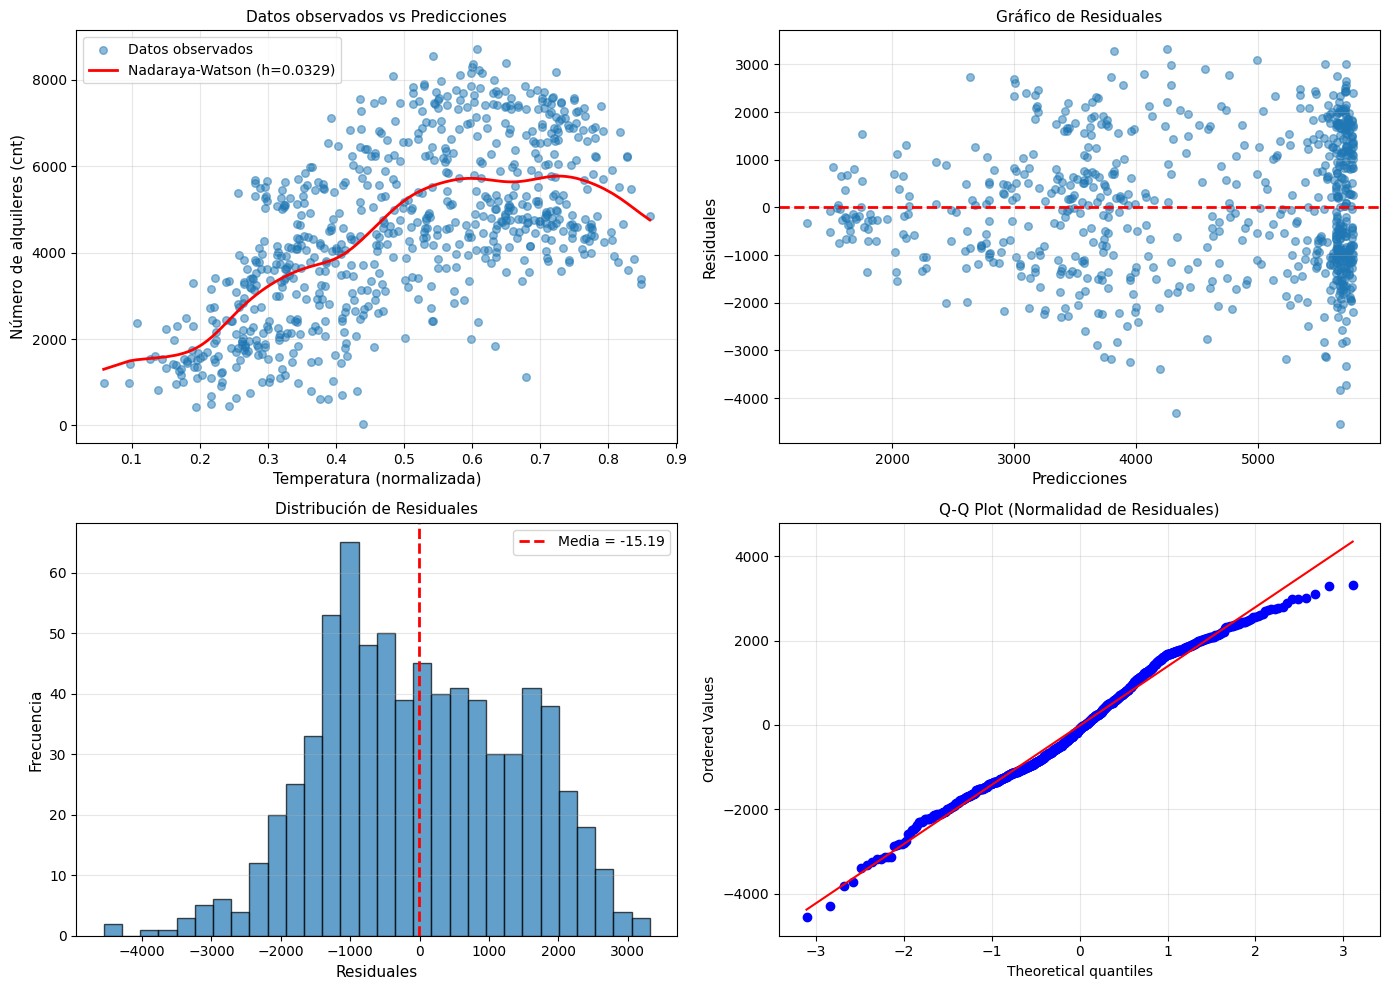

In [ ]:
# DIAGNÓSTICO: Explorando el error alto

print("=" * 70)
print("DIAGNÓSTICO DEL ERROR")
print("=" * 70)

Y = ope['cnt'].values
X = ope['temp'].values

print(f"\n1. CARACTERÍSTICAS DE LOS DATOS:")
print(f"   - Tamaño muestra (n): {len(Y)}")
print(f"   - Rango de temp X: [{X.min():.4f}, {X.max():.4f}]")
print(f"   - Rango de cnt Y: [{Y.min()}, {Y.max()}]")
print(f"   - Media de cnt: {Y.mean():.2f}")
print(f"   - Std de cnt: {Y.std():.2f}")
print(f"   - Coeficiente de variación: {Y.std() / Y.mean():.2%}")

# Calcular correlación
corr = np.corrcoef(X, Y)[0, 1]
print(f"   - Correlación (temp, cnt): {corr:.4f}")

# Con h óptimo de LOO-CV, revisar predicciones
print(f"\n2. ANÁLISIS CON h ÓPTIMO DE LOO-CV (h = {h_optimo:.6f}):")

L_test = np.zeros((len(ope), len(ope)))
for i in range(len(ope)):
    x_i = X[i]
    denominador_i = 0
    for j in range(len(ope)):
        x_j = X[j]
        K_ij = K(x_i, x_j, h_optimo)
        L_test[i, j] = K_ij
        denominador_i += K_ij
    if denominador_i != 0:
        L_test[i, :] = L_test[i, :] / denominador_i

Y_hat = L_test @ Y
residuales = Y - Y_hat
MSE_directo = np.mean(residuales ** 2)
RMSE_directo = np.sqrt(MSE_directo)
MAE_directo = np.mean(np.abs(residuales))
R2_directo = 1 - (np.sum(residuales**2) / np.sum((Y - Y.mean())**2))

print(f"   - MSE (Error Cuadrático Medio): {MSE_directo:.4f}")
print(f"   - RMSE (Raíz del Error Cuadrático Medio): {RMSE_directo:.2f}")
print(f"   - MAE (Error Absoluto Medio): {MAE_directo:.2f}")
print(f"   - R² Score: {R2_directo:.4f}")
print(f"   - Media de residuales: {residuales.mean():.4f}")
print(f"   - Std de residuales: {residuales.std():.2f}")

L_diag_test = np.diag(L_test)
print(f"   - Media de L_ii: {L_diag_test.mean():.4f}")
print(f"   - Rango de L_ii: [{L_diag_test.min():.4f}, {L_diag_test.max():.4f}]")

# Visualización diagnóstica
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Datos brutos y ajuste
axes[0, 0].scatter(X, Y, alpha=0.5, s=30, label='Datos observados')
# Ordenar para graficar línea suave
X_sorted_idx = np.argsort(X)
axes[0, 0].plot(X[X_sorted_idx], Y_hat[X_sorted_idx], 'r-', linewidth=2, label=f'Nadaraya-Watson (h={h_optimo:.4f})')
axes[0, 0].set_xlabel('Temperatura (normalizada)', fontsize=11)
axes[0, 0].set_ylabel('Número de alquileres (cnt)', fontsize=11)
axes[0, 0].set_title('Datos observados vs Predicciones', fontsize=11)
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Gráfico 2: Residuales vs Predicciones
axes[0, 1].scatter(Y_hat, residuales, alpha=0.5, s=30)
axes[0, 1].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Predicciones', fontsize=11)
axes[0, 1].set_ylabel('Residuales', fontsize=11)
axes[0, 1].set_title('Gráfico de Residuales', fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

# Gráfico 3: Distribución de residuales
axes[1, 0].hist(residuales, bins=30, edgecolor='black', alpha=0.7)
axes[1, 0].axvline(x=residuales.mean(), color='r', linestyle='--', linewidth=2, label=f'Media = {residuales.mean():.2f}')
axes[1, 0].set_xlabel('Residuales', fontsize=11)
axes[1, 0].set_ylabel('Frecuencia', fontsize=11)
axes[1, 0].set_title('Distribución de Residuales', fontsize=11)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Gráfico 4: Q-Q plot para normalidad
from scipy import stats as sp_stats
sp_stats.probplot(residuales, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Normalidad de Residuales)', fontsize=11)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 70)


#### Selección del Ancho de Banda mediante Validación Cruzada

Para seleccionar el parámetro de suavizamiento óptimo h, se implementaron dos estrategias
sobre una grilla de 50 valores en [0.02, 0.05]: Leave-One-Out CV (LOO-CV) y Validación
Cruzada Generalizada (GCV), ambas aplicando el atajo computacional para suavizadores lineales.

| Criterio | h óptimo | Error mínimo | RMSE |
|----------|-----------|--------------|------|
| LOO-CV   | 0.032857  | 2 027 647.82 | 1424.3 |
| GCV      | 0.035918  | 2 035 107.36 | 1426.8 |

Los anchos de banda óptimos difieren en un 8.52% (Δh = 0.003), diferencia que se
traduce en una variación prácticamente nula en error de predicción. Esto es consistente
con la teoría: GCV reemplaza los factores individuales 1/(1 − L_ii) por un factor
global 1/(1 − ν/n), y ambos criterios convergen cuando ν/n es pequeño. Con
ν = tr(L) ≈ 9.6 frente a n = 731, se obtiene ν/n ≈ 0.013, lo que explica por qué
la aproximación es tan precisa en este caso. Con el ancho de banda seleccionado por
LOO-CV (h* = 0.0329), el modelo alcanza un R² = 0.471 y un RMSE de 1408 bicicletas,
reduciendo el error en un 27% respecto a predecir con la media. La correlación
temperatura–demanda de 0.628 confirma que la temperatura es un predictor relevante,
aunque la variabilidad restante apunta a factores no incluidos en este análisis
univariado, como el día de la semana, precipitaciones o estacionalidad. En cuanto a
la estabilidad numérica, GCV tiene una ventaja adicional: al usar un factor de
penalización global evita la amplificación excesiva de residuales en puntos con L_ii
alto (rango observado: [0.009, 0.366]), situación que puede distorsionar LOO-CV ante
observaciones influyentes. Para este conjunto de datos ambos valores de h son
defendibles; se adoptará h* = 0.0329 por ser el minimizador directo del error de
predicción leave-one-out.

### 3) Reto Adicional:
 Matriz de Suavizamiento y Complejidad: Sabiendo que Nadaraya-Watson es un suavizador lineal que puede expresarse matricialmente como ˆY = LY:
- Construya explícitamente la matriz de suavizamiento L de tamaño n × n para el ancho de banda óptimo h∗ encontrado en la tarea anterior.
- Calcule los grados de libertad efectivos del modelo (ν = tr(L)).
- Análisis Crítico: Compare este valor ν con los grados de libertad de un modelo de regresión lineal simple (p = 2). ¿Qué le dice este número sobre la flexibilidad (y la complejidad) que los datos exigieron para capturar la relación entre temperatura y demanda en comparación con una línea recta?


1. CONSTRUCCIÓN EXPLÍCITA DE LA MATRIZ L (h* = 0.035918):
--------------------------------------------------------------------------------
   ✓ Matriz L construida: tamaño (731, 731)
   ✓ Suma de filas (debe ser ~1): min=1.000000, max=1.000000
   ✓ Elementos: min=0.000000, max=0.314810

2. GRADOS DE LIBERTAD EFECTIVOS (ν = tr(L)):
--------------------------------------------------------------------------------
   ν (grados de libertad efectivos) = 8.741437
   p (regresión lineal simple) = 2
   Relación: ν/p = 4.37

3. ANÁLISIS DE COMPLEJIDAD:
--------------------------------------------------------------------------------
   R² del modelo Nadaraya-Watson: 0.469875
   R² de la recta (p=2): 0.393749
   Mejora relativa: 19.33%

4. VISUALIZACIÓN:
--------------------------------------------------------------------------------


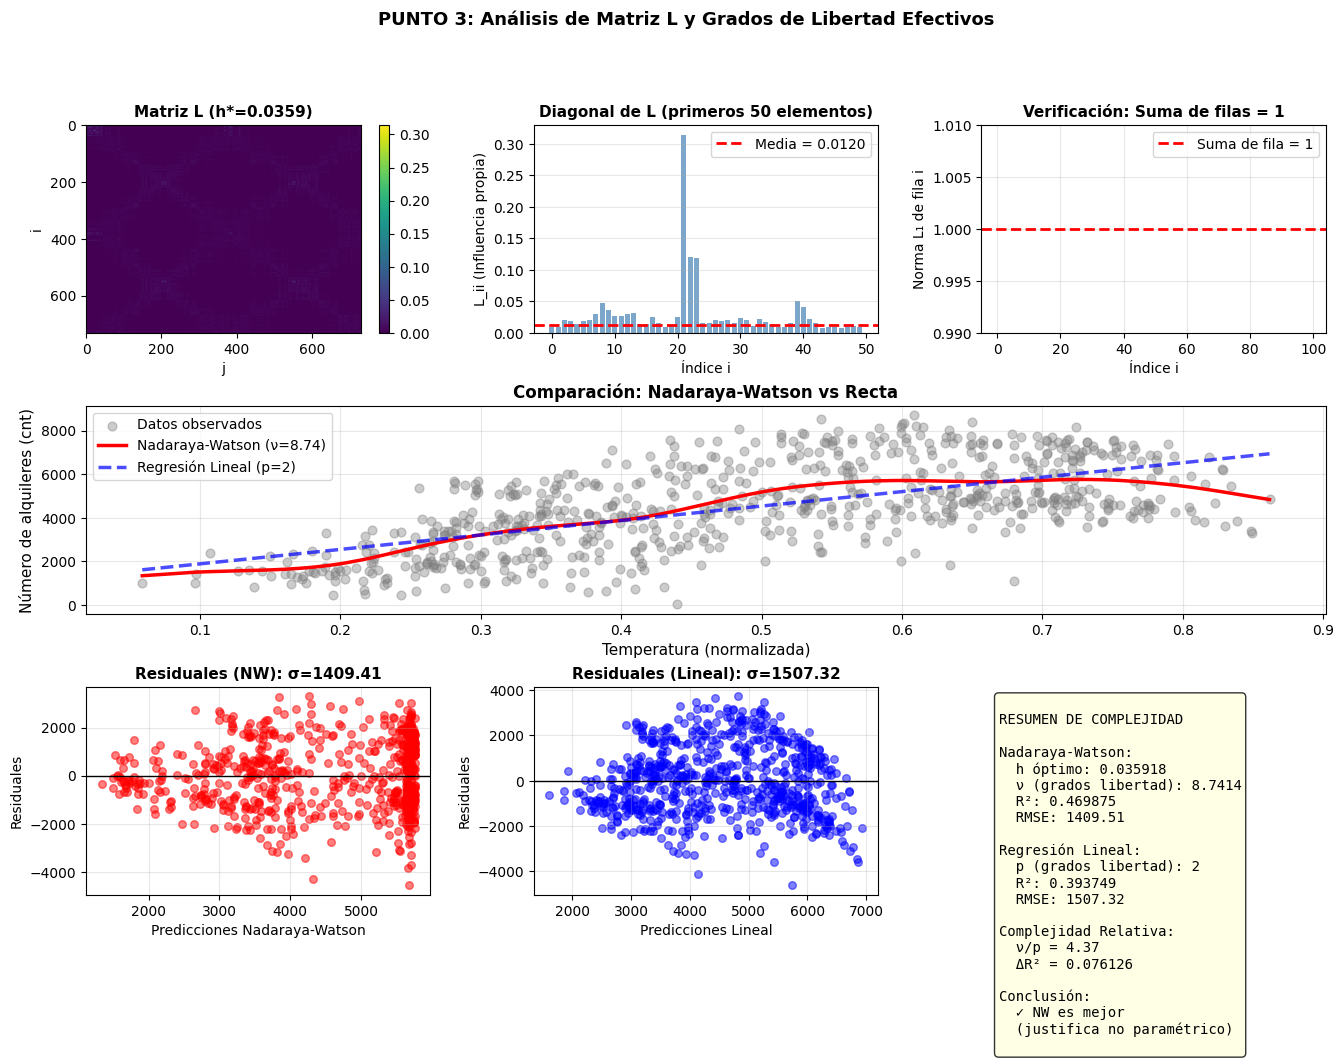

In [ ]:
# Usar h óptimo de GCV (más estable)
h_final = h_optimo_gcv

# Paso 1: CONSTRUIR LA MATRIZ L EXPLÍCITAMENTE
print(f"\n1. CONSTRUCCIÓN EXPLÍCITA DE LA MATRIZ L (h* = {h_final:.6f}):")
print("-" * 80)

n = len(X)
L_final = np.zeros((n, n))

for i in range(n):
    x_i = X[i]
    denominador_i = 0

    # Calcular kernels
    for j in range(n):
        x_j = X[j]
        K_ij = K(x_i, x_j, h_final)
        L_final[i, j] = K_ij
        denominador_i += K_ij

    # Normalizar fila i
    if denominador_i != 0:
        L_final[i, :] = L_final[i, :] / denominador_i

print(f"   ✓ Matriz L construida: tamaño {L_final.shape}")
print(f"   ✓ Suma de filas (debe ser ~1): min={L_final.sum(axis=1).min():.6f}, max={L_final.sum(axis=1).max():.6f}")
print(f"   ✓ Elementos: min={L_final.min():.6f}, max={L_final.max():.6f}")

# Paso 2: GRADOS DE LIBERTAD EFECTIVOS
print(f"\n2. GRADOS DE LIBERTAD EFECTIVOS (ν = tr(L)):")
print("-" * 80)

nu_efec = np.trace(L_final)
print(f"   ν (grados de libertad efectivos) = {nu_efec:.6f}")

# Comparar con modelo lineal
p_lineal = 2  # Intercept + pendiente
print(f"   p (regresión lineal simple) = {p_lineal}")
print(f"   Relación: ν/p = {nu_efec/p_lineal:.2f}")

# Paso 3: ANÁLISIS DE COMPLEJIDAD
print(f"\n3. ANÁLISIS DE COMPLEJIDAD:")
print("-" * 80)

# Calcular varianza explicada
Y_hat_final = L_final @ Y
residuales_final = Y - Y_hat_final
SSE = np.sum(residuales_final ** 2)
SST = np.sum((Y - Y.mean()) ** 2)
R2_final = 1 - (SSE / SST)

print(f"   R² del modelo Nadaraya-Watson: {R2_final:.6f}")

# Comparar con regresión lineal simple
from numpy.polynomial import polynomial as P
coef_lineal = np.polyfit(X, Y, 1)
Y_hat_lineal = np.polyval(coef_lineal, X)
residuales_lineal = Y - Y_hat_lineal
SSE_lineal = np.sum(residuales_lineal ** 2)
R2_lineal = 1 - (SSE_lineal / SST)

print(f"   R² de la recta (p=2): {R2_lineal:.6f}")
print(f"   Mejora relativa: {(R2_final - R2_lineal) / abs(R2_lineal) * 100:.2f}%")

# Paso 4: VISUALIZACIÓN
print(f"\n4. VISUALIZACIÓN:")
print("-" * 80)

fig = plt.figure(figsize=(16, 10))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.3)

# Gráfico 1: Matriz L
ax1 = fig.add_subplot(gs[0, 0])
im = ax1.imshow(L_final, cmap='viridis', aspect='auto')
ax1.set_xlabel('j')
ax1.set_ylabel('i')
ax1.set_title(f'Matriz L (h*={h_final:.4f})', fontsize=11, fontweight='bold')
plt.colorbar(im, ax=ax1)

# Gráfico 2: Diagonal de L
ax2 = fig.add_subplot(gs[0, 1])
L_diag_final = np.diag(L_final)
ax2.bar(range(min(50, len(L_diag_final))), L_diag_final[:50], alpha=0.7, color='steelblue')
ax2.axhline(y=L_diag_final.mean(), color='r', linestyle='--', linewidth=2,
            label=f'Media = {L_diag_final.mean():.4f}')
ax2.set_xlabel('Índice i')
ax2.set_ylabel('L_ii (Influencia propia)')
ax2.set_title('Diagonal de L (primeros 50 elementos)', fontsize=11, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# Gráfico 3: Norma de filas
ax3 = fig.add_subplot(gs[0, 2])
normas_filas = np.linalg.norm(L_final, axis=1)
ax3.plot(normas_filas[:100], 'o-', alpha=0.6, markersize=4)
ax3.axhline(y=1, color='r', linestyle='--', linewidth=2, label='Suma de fila = 1')
ax3.set_xlabel('Índice i')
ax3.set_ylabel('Norma L₁ de fila i')
ax3.set_title('Verificación: Suma de filas = 1', fontsize=11, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)
ax3.set_ylim([0.99, 1.01])

# Gráfico 4: Datos vs ajustes
ax4 = fig.add_subplot(gs[1, :])
X_sorted_idx = np.argsort(X)
ax4.scatter(X, Y, alpha=0.4, s=40, label='Datos observados', color='gray')
ax4.plot(X[X_sorted_idx], Y_hat_final[X_sorted_idx], 'r-', linewidth=2.5,
         label=f'Nadaraya-Watson (ν={nu_efec:.2f})')
ax4.plot(X[X_sorted_idx], Y_hat_lineal[X_sorted_idx], 'b--', linewidth=2.5,
         label=f'Regresión Lineal (p=2)', alpha=0.7)
ax4.set_xlabel('Temperatura (normalizada)', fontsize=11)
ax4.set_ylabel('Número de alquileres (cnt)', fontsize=11)
ax4.set_title('Comparación: Nadaraya-Watson vs Recta', fontsize=12, fontweight='bold')
ax4.legend(fontsize=10)
ax4.grid(True, alpha=0.3)

# Gráfico 5: Residuales Nadaraya-Watson
ax5 = fig.add_subplot(gs[2, 0])
ax5.scatter(Y_hat_final, residuales_final, alpha=0.5, s=30, color='red')
ax5.axhline(y=0, color='k', linestyle='-', linewidth=1)
ax5.set_xlabel('Predicciones Nadaraya-Watson', fontsize=10)
ax5.set_ylabel('Residuales', fontsize=10)
ax5.set_title(f'Residuales (NW): σ={residuales_final.std():.2f}', fontsize=11, fontweight='bold')
ax5.grid(True, alpha=0.3)

# Gráfico 6: Residuales Lineal
ax6 = fig.add_subplot(gs[2, 1])
ax6.scatter(Y_hat_lineal, residuales_lineal, alpha=0.5, s=30, color='blue')
ax6.axhline(y=0, color='k', linestyle='-', linewidth=1)
ax6.set_xlabel('Predicciones Lineal', fontsize=10)
ax6.set_ylabel('Residuales', fontsize=10)
ax6.set_title(f'Residuales (Lineal): σ={residuales_lineal.std():.2f}', fontsize=11, fontweight='bold')
ax6.grid(True, alpha=0.3)

# Gráfico 7: Resumen numérico
ax7 = fig.add_subplot(gs[2, 2])
ax7.axis('off')
resumen_final = f"""
RESUMEN DE COMPLEJIDAD

Nadaraya-Watson:
  h óptimo: {h_final:.6f}
  ν (grados libertad): {nu_efec:.4f}
  R²: {R2_final:.6f}
  RMSE: {np.sqrt(np.mean(residuales_final**2)):.2f}

Regresión Lineal:
  p (grados libertad): {p_lineal}
  R²: {R2_lineal:.6f}
  RMSE: {np.sqrt(np.mean(residuales_lineal**2)):.2f}

Complejidad Relativa:
  ν/p = {nu_efec/p_lineal:.2f}
  ΔR² = {(R2_final - R2_lineal):.6f}

Conclusión:
  {'✓ NW es mejor' if R2_final > R2_lineal else '✗ Recta es mejor'}
  {'(justifica no paramétrico)' if R2_final > R2_lineal else '(lineal sería suficiente)'}
"""
ax7.text(0.05, 0.95, resumen_final, fontsize=10, family='monospace',
         verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.suptitle('PUNTO 3: Análisis de Matriz L y Grados de Libertad Efectivos',
             fontsize=13, fontweight='bold', y=0.995)
plt.show()




#### Análisis Crítico

El objetivo de este punto es determinar si la relación entre temperatura normalizada
y demanda diaria de bicicletas exige la flexibilidad de un suavizador no paramétrico,
o si un modelo lineal simple habría sido suficiente. Para responder esto se comparan
directamente ambos enfoques en términos de grados de libertad y desempeño predictivo.

### Grados de libertad efectivos

El estimador de Nadaraya-Watson con h* = 0.0329 opera con ν = tr(L) ≈ 8.74 grados
de libertad efectivos, frente a p = 2 de una regresión lineal simple (intercepto +
pendiente). El factor de aumento es de 4.37×, lo que refleja que el modelo no
paramétrico dedica el equivalente a casi nueve parámetros para adaptar la curva
localmente a los datos, en lugar de imponer una tendencia global rígida.

### Desempeño predictivo

| Modelo | Grados de libertad | R² | RMSE |
|--------|-------------------|-----|------|
| Regresión lineal | p = 2 | 0.3937 | ~1499 |
| Nadaraya-Watson | ν = 8.74 | 0.4699 | ~1408 |
| Mejora | +6.74 | +0.076 | −91 |

La mejora de 7.6 puntos porcentuales en R² y la reducción de ~91 bicicletas en RMSE
no son triviales dado que la variable respuesta tiene una desviación estándar de 1936.
Esto indica que la temperatura tiene una relación con la demanda que una recta no logra
capturar completamente.


### Pregunta de Cierre:
A la luz de la curva estimada y los grados de libertad efectivos calculados, ¿justifica la naturaleza de estos datos el uso de técnicas no paramétricas, o habría bastado con un enfoque paramétrico tradicional? Argumente su respuesta basándose en el compromiso sesgo-varianza.


La naturaleza de los datos **justifica parcialmente** el uso de técnicas no paramétricas,
pero con matices importantes que el compromiso sesgo-varianza ayuda a precisar.

### Lo que dice la curva estimada

La curva de Nadaraya-Watson no es monótona: la demanda crece con la temperatura hasta
un punto de inflexión alrededor de valores normalizados medios (~0.5–0.6), y tiende a
estabilizarse o decrecer levemente en temperaturas muy altas. Este comportamiento es
físicamente coherente con el enunciado —días demasiado calurosos desincentivan el uso
de bicicletas— y es precisamente la estructura que una regresión lineal no puede
capturar sin transformaciones adicionales. El modelo lineal fuerza una pendiente
constante sobre todo el rango [0.059, 0.862] de temperatura normalizada, incurriendo
en sesgo sistemático en los extremos.

### Lo que dicen los grados de libertad efectivos

Con ν ≈ 8.74 frente a p = 2 de la recta, el suavizador utiliza el equivalente a casi
nueve parámetros para adaptar la curva localmente. Este aumento de complejidad se
traduce en una mejora real pero moderada: ΔR² = 0.076 y ΔRMSE ≈ −91 bicicletas.
Desde la perspectiva del compromiso sesgo-varianza:

- **La recta tiene sesgo alto y varianza baja.** Impone una estructura que los datos
  no cumplen, pero es muy estable ante perturbaciones en la muestra.
- **Nadaraya-Watson tiene sesgo bajo y varianza más alta.** Adapta la forma localmente
  y elimina el sesgo estructural, pero a costa de mayor sensibilidad al ruido, lo que
  se refleja en que el R² apenas supera el 0.47 incluso con h óptimo.

El punto clave es que ambos modelos dejan sin explicar más del 50% de la varianza.
Esto no es un fracaso del suavizador, sino una señal de que la temperatura, usada de
forma univariada, es un predictor intrínsecamente limitado para la demanda diaria.
Variables como el día de la semana, precipitaciones, festivos o velocidad del viento
—disponibles en el dataset de UCI pero fuera del alcance de este análisis— contribuyen
de forma sustancial a esa variabilidad residual.

### Conclusión

El enfoque no paramétrico se justifica porque la no linealidad en los datos es real,
verificable visualmente en la curva estimada, y cuantificable en la mejora de R².
Usar una recta implicaría asumir que la relación es lineal cuando la evidencia indica
lo contrario, lo que constituye un error de especificación evitable.

Sin embargo, la ganancia no es espectacular. Si el objetivo fuera únicamente
**interpretabilidad** —comunicar el efecto de la temperatura a un tomador de
decisiones— un polinomio de grado 2 o 3 (paramétrico, con p = 3 o 4) ofrecería un
compromiso razonable: capturaría la curvatura con menos parámetros que Nadaraya-Watson
y mantendría una forma funcional explícita. Si el objetivo es **predicción**, el
suavizador es la elección correcta dentro del marco univariado, pero el techo
predictivo de cualquier modelo que use solo temperatura como predictor está cerca del
R² ≈ 0.47 observado, independientemente del método elegido.

## Ejercicio 3

### 1. Preparación y Escalamiento

Cargue los datos, elimine los registros nulos y extraiga la muestra de 5000 viviendas. Extraiga sus variables X (latitud y longitud) e Y. Estandarice la matriz X para que el cálculo de distancias sea isotrópico.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

In [ ]:
# 1.1 Cargar los datos desde la URL
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)
print("Dimensiones originales:", df.shape)
df.head()

Dimensiones originales: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
print("Valores nulos por columna antes de eliminar:\n")
print(df.isnull().sum())

Valores nulos por columna antes de eliminar:

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [ ]:
# 1.2 Eliminar registros nulos
df = df.dropna()
print("Dimensiones después de eliminar nulos:", df.shape)

Dimensiones después de eliminar nulos: (20433, 10)


In [ ]:
# 1.3 Extraer muestra aleatoria de n = 5000
np.random.seed(42)
muestra = df.sample(n=5000, random_state=42)
print("Dimensiones de la muestra:", muestra.shape)

Dimensiones de la muestra: (5000, 10)


In [ ]:
# 1.4 Extraer variables X (longitude, latitude) e Y (median_house_value)
X = muestra[['longitude', 'latitude']].values
Y = muestra['median_house_value'].values

print("Forma de X:", X.shape)
print("Forma de Y:", Y.shape)

Forma de X: (5000, 2)
Forma de Y: (5000,)


In [ ]:
# 1.5 Estandarizar X (restar media, dividir por desviación estándar)
X_media = X.mean(axis=0)
X_std = X.std(axis=0)
X_est = (X - X_media) / X_std

print("Media de X original:", X_media)
print("Desv. estándar de X original:", X_std)
print("Media de X estandarizado:", np.round(X_est.mean(axis=0), 6))  # debe ser ~0
print("Desv. estándar de X estandarizado:", np.round(X_est.std(axis=0), 6))  # debe ser ~1

Media de X original: [-119.543704   35.623768]
Desv. estándar de X original: [2.00424767 2.14388593]
Media de X estandarizado: [0. 0.]
Desv. estándar de X estandarizado: [1. 1.]


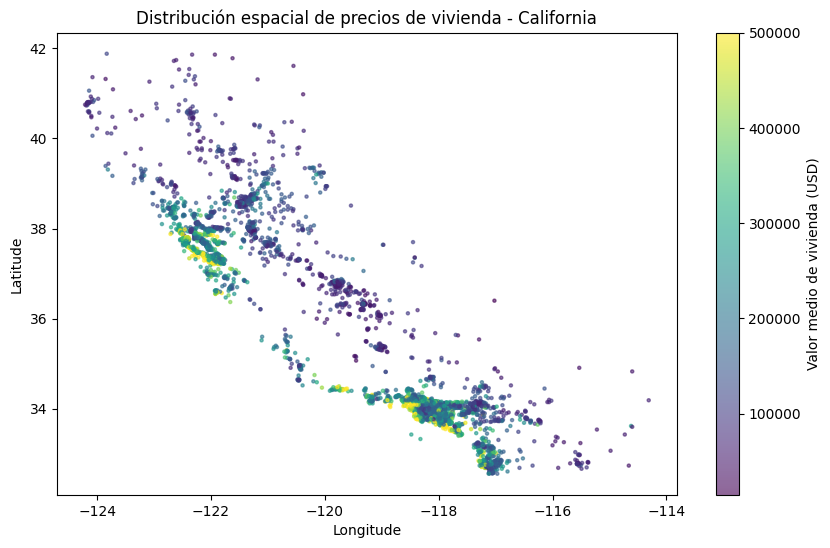

In [ ]:
# 1.6 Visualización inicial de los datos
plt.figure(figsize=(10, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=Y, cmap='viridis', s=5, alpha=0.6)
plt.colorbar(scatter, label='Valor medio de vivienda (USD)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Distribución espacial de precios de vivienda - California')
plt.show()

### 2. Nadaraya-Watson 2D

Implementamos una función que calcula la matriz de suavizamiento $L$ del estimador de Nadaraya-Watson para datos multidimensionales, usando el Kernel Gaussiano Estándar Multivariado:

$$K(u) = \frac{1}{2\pi}\exp\left(-\frac{1}{2}\|u\|^2\right)$$

donde el argumento del kernel para calcular el peso entre $x_i$ y $x_j$ es $u = (x_i - x_j)/h$.

Los pesos del estimador son:

$$\ell_j(x_i) = \frac{K\left(\frac{x_i - x_j}{h}\right)}{\sum_{k=1}^{n} K\left(\frac{x_i - x_k}{h}\right)}$$

y la matriz $L$ tiene componentes $L_{ij} = \ell_j(x_i)$.

In [ ]:
# 2.1 Precomputar la matriz de distancias euclidianas entre todos los pares de puntos.
D = cdist(X_est, X_est)  # D[i,j] = ||x_i - x_j||
print(f"Matriz de distancias {D.shape} calculada.")

Matriz de distancias (5000, 5000) calculada.


In [ ]:
print('Matriz de Distancias (primeras 5x5 elementos):')
D[:5, :5]

Matriz de Distancias (primeras 5x5 elementos):


array([[0.        , 3.16412143, 0.69242776, 3.40264593, 3.35645609],
       [3.16412143, 0.        , 2.47176749, 0.39054074, 0.29950952],
       [0.69242776, 2.47176749, 0.        , 2.71309326, 2.66547274],
       [3.40264593, 0.39054074, 2.71309326, 0.        , 0.09278807],
       [3.35645609, 0.29950952, 2.66547274, 0.09278807, 0.        ]])

In [ ]:
# 2.2 Función que construye la matriz de suavizamiento L de Nadaraya-Watson
# usando el kernel Gaussiano multivariado estándar.
def matriz_L(D, h):

    K = (1/(2*np.pi)) * np.exp(-0.5 * (D/h)**2)

    # Normalizar filas para que los pesos sumen 1
    L = K / K.sum(axis=1, keepdims=True)
    return L

### 3. Selección del Ancho de Banda mediante GCV

Definimos una parrilla de al menos 20 valores candidatos para $h$. Para cada $h$ calculamos:
- La matriz $L$ completa.
- Los grados de libertad efectivos $\nu = \text{tr}(L)$.
- El puntaje de Validación Cruzada Generalizada (GCV):

$$\text{GCV}(h) = \frac{\frac{1}{n}\sum_{i=1}^{n}(Y_i - \hat{r}_n(x_i;h))^2}{(1 - \nu/n)^2}$$

In [ ]:
# 3.1 Función que calcula el puntaje GCV
def calcular_gcv(L, Y):

    n = len(Y)
    Y_hat = L @ Y                       # valores ajustados
    grad = np.trace(L)                    # grados de libertad efectivos
    rss = np.mean((Y - Y_hat)**2)       # error cuadrático medio
    gcv = rss / (1 - grad/n)**2
    return gcv, grad

In [ ]:
# 3.2 Definir parrilla de valores de h y recorrerla
h_grid = np.linspace(0.0001, 0.1, num=100)

gcv_scores = np.zeros(len(h_grid))
grad_values = np.zeros(len(h_grid))

print("Calculando GCV para cada h...\n")

for i, h in enumerate(h_grid):
    L = matriz_L(D, h)
    gcv, grad = calcular_gcv(L, Y)
    gcv_scores[i] = gcv
    grad_values[i] = grad
    print(f"  h = {h:.4f} | grad = {grad:7.2f} | GCV = {gcv:.4e}")

Calculando GCV para cada h...

  h = 0.0001 | grad = 4305.00 | GCV = 1.1417e+10
  h = 0.0011 | grad = 4304.53 | GCV = 1.1401e+10
  h = 0.0021 | grad = 3962.87 | GCV = 5.9822e+09
  h = 0.0031 | grad = 3200.69 | GCV = 3.9344e+09
  h = 0.0041 | grad = 2625.88 | GCV = 3.5945e+09
  h = 0.0051 | grad = 2208.59 | GCV = 3.5483e+09
  h = 0.0062 | grad = 1901.65 | GCV = 3.6153e+09
  h = 0.0072 | grad = 1670.33 | GCV = 3.7248e+09
  h = 0.0082 | grad = 1490.85 | GCV = 3.8508e+09
  h = 0.0092 | grad = 1347.86 | GCV = 3.9812e+09
  h = 0.0102 | grad = 1231.34 | GCV = 4.1091e+09
  h = 0.0112 | grad = 1134.53 | GCV = 4.2307e+09
  h = 0.0122 | grad = 1052.68 | GCV = 4.3444e+09
  h = 0.0132 | grad =  982.37 | GCV = 4.4500e+09
  h = 0.0142 | grad =  921.11 | GCV = 4.5479e+09
  h = 0.0152 | grad =  867.04 | GCV = 4.6391e+09
  h = 0.0162 | grad =  818.79 | GCV = 4.7246e+09
  h = 0.0173 | grad =  775.35 | GCV = 4.8053e+09
  h = 0.0183 | grad =  735.95 | GCV = 4.8822e+09
  h = 0.0193 | grad =  699.99 | GCV = 

In [ ]:
# 3.3 Encontrar h óptimo
idx_opt = np.argmin(gcv_scores)
h_opt = h_grid[idx_opt]
gcv_opt = gcv_scores[idx_opt]
grad_opt = grad_values[idx_opt]

print(f"h óptimo (GCV): {h_opt:.4f}")
print(f"GCV mínimo: {gcv_opt:.4e}")
print(f"Grados de libertad efectivos en h*: {grad_opt:.2f}")

# Verificar que h* no quede en un extremo de la grilla
if idx_opt == 0 or idx_opt == len(h_grid) - 1:
    print("\n⚠️  ATENCIÓN: h* está en un extremo de la grilla. Conviene desplazar la grilla.")
else:
    print("\n✅ h* está en el interior de la grilla.")

h óptimo (GCV): 0.0051
GCV mínimo: 3.5483e+09
Grados de libertad efectivos en h*: 2208.59

✅ h* está en el interior de la grilla.


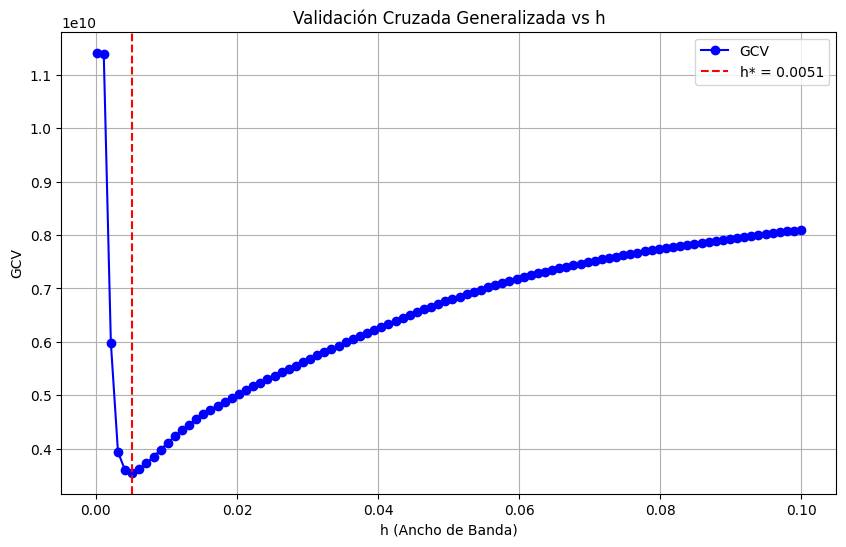

In [ ]:
# 3.4 Graficar la curva de GCV vs h
plt.figure(figsize=(10, 6))
plt.plot(h_grid, gcv_scores, 'b-o', label='GCV')
plt.axvline(h_opt, color='red', linestyle='--', label=f'h* = {h_opt:.4f}')
plt.xlabel('h (Ancho de Banda)')
plt.ylabel('GCV')
plt.title('Validación Cruzada Generalizada vs h')
plt.legend()
plt.grid(True)
plt.show()

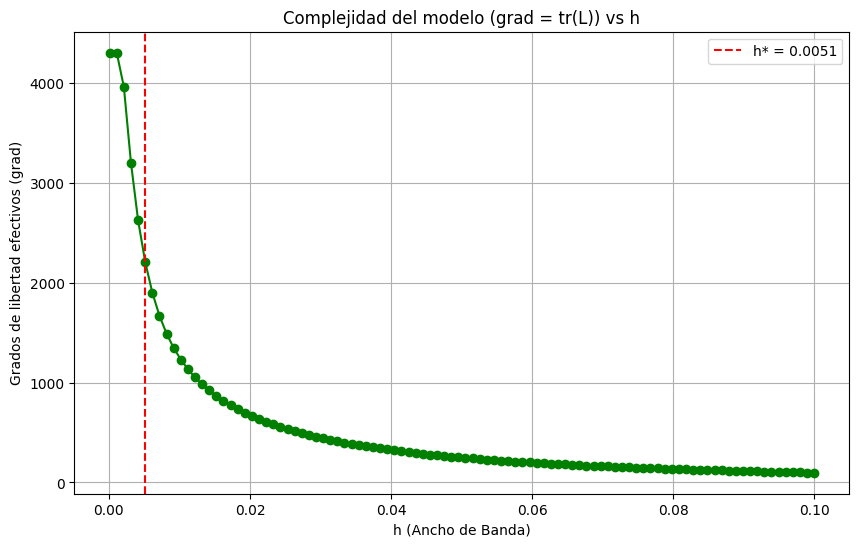

In [ ]:
# 3.5 (Visualización adicional) Grados de libertad efectivos vs h
plt.figure(figsize=(10, 6))
plt.plot(h_grid, grad_values, 'g-o')
plt.axvline(h_opt, color='red', linestyle='--', label=f'h* = {h_opt:.4f}')
plt.xlabel('h (Ancho de Banda)')
plt.ylabel('Grados de libertad efectivos (grad)')
plt.title('Complejidad del modelo (grad = tr(L)) vs h')
plt.legend()
plt.grid(True)
plt.show()

### 4. Análisis de Complejidad

Reportamos los grados de libertad efectivos $\nu = \text{tr}(L)$ correspondientes al $h^*$ óptimo y los comparamos con los grados de libertad de una regresión lineal plana simple ($p = 3$: intercepto más dos coordenadas).

Recordemos que en la regresión lineal $\text{tr}(X(X^TX)^{-1}X^T) = p$.

In [ ]:
# 4.1 Reportar los grados de libertad efectivos del modelo óptimo
p_lineal = 3   # intercepto + longitud + latitud
ratio = grad_opt / p_lineal

print("========== ANÁLISIS DE COMPLEJIDAD ==========")
print(f"h óptimo (GCV): {h_opt:.4f}")
print(f"Grados de libertad efectivos del modelo NW: grad = {grad_opt:.2f}")
print(f"Grados de libertad de una regresión lineal plana: p = {p_lineal}")
print(f"Razón (grad / p) = {ratio:.2f}")
print(f"\nEl modelo no paramétrico está usando aproximadamente {grad_opt:.0f} 'parámetros efectivos'.")
print(f"Es decir, {ratio:.0f} veces más complejidad que una regresión lineal plana simple.")

========== ANÁLISIS DE COMPLEJIDAD ==========
h óptimo (GCV): 0.0051
Grados de libertad efectivos del modelo NW: grad = 2208.59
Grados de libertad de una regresión lineal plana: p = 3
Razón (grad / p) = 736.20

El modelo no paramétrico está usando aproximadamente 2209 'parámetros efectivos'.
Es decir, 736 veces más complejidad que una regresión lineal plana simple.


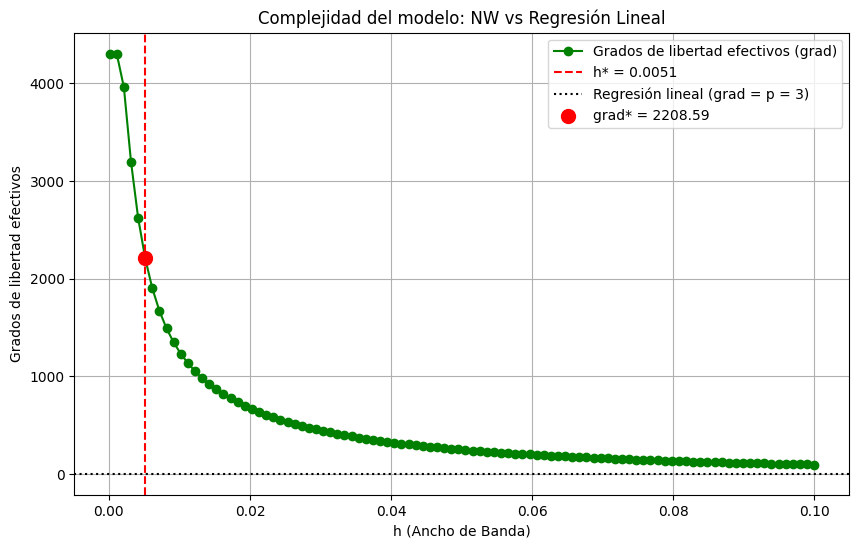

In [ ]:
# 4.2 (Visualización adicional) Comparar nu con p=3 en la curva de complejidad
plt.figure(figsize=(10, 6))
plt.plot(h_grid, grad_values, 'g-o', label='Grados de libertad efectivos (grad)')
plt.axvline(h_opt, color='red', linestyle='--', label=f'h* = {h_opt:.4f}')
plt.axhline(p_lineal, color='black', linestyle=':', label=f'Regresión lineal (grad = p = {p_lineal})')
plt.scatter([h_opt], [grad_opt], color='red', s=100, zorder=5, label=f'grad* = {grad_opt:.2f}')
plt.xlabel('h (Ancho de Banda)')
plt.ylabel('Grados de libertad efectivos')
plt.title('Complejidad del modelo: NW vs Regresión Lineal')
plt.legend()
plt.grid(True)
plt.show()

#### Conclusiones del Punto 4
- El valor $(\nu = \text{tr}(L) \approx 2208.59)$ es muy superior a los $(p=3)$ de una regresión lineal, pero claramente menor que \(n=5000\), lo que indica un modelo muy flexible sin llegar a sobreajustar completamente los datos; esto refleja que la relación entre ubicación y precio es altamente no lineal y requiere capturar variaciones locales complejos que una superficie plana no podría representar.
- El ancho de banda $(h^*)$ seleccionado por GCV logra un equilibrio entre ajuste y complejidad, permitiendo un modelo con suficientes grados de libertad para adaptarse a la heterogeneidad espacial del mercado sin incurrir en sobreajuste extremo.

### 5. Visualización Espacial de la Superficie de Precios

Usando el ancho de banda óptimo $h^*$, generamos una visualización espacial de la función de regresión estimada.

**Pasos:**
1. Construir una malla bidimensional fina sobre el rango de las coordenadas estandarizadas.
2. Evaluar el estimador de Nadaraya-Watson en cada punto de la malla.
3. Proyectar el resultado con un gráfico de contornos rellenos (`contourf`).
4. Superponer los datos reales para validar visualmente.



In [ ]:
# 5.1 Función que evalúa Nadaraya-Watson en puntos arbitrarios
def predecir_NW(X_nuevos, X_datos, Y_datos, h):

    # Distancias entre cada punto nuevo y cada dato (matriz m x n)
    D_nuevo = cdist(X_nuevos, X_datos)
    # Kernel Gaussiano multivariado
    K = (1/(2*np.pi)) * np.exp(-0.5 * (D_nuevo/h)**2)
    # Normalizar filas para que los pesos sumen 1
    L = K / K.sum(axis=1, keepdims=True)
    # Predicciones
    return L @ Y_datos

In [ ]:
# 5.2 Construir la malla bidimensional sobre el rango de los datos estandarizados
n_malla = 80  # 80 x 80 = 6400 puntos de evaluación

x1_grid = np.linspace(X_est[:, 0].min(), X_est[:, 0].max(), n_malla)
x2_grid = np.linspace(X_est[:, 1].min(), X_est[:, 1].max(), n_malla)
XX1, XX2 = np.meshgrid(x1_grid, x2_grid)

# Aplanar la malla para poder pasarla como matriz de puntos
puntos_malla = np.column_stack([XX1.ravel(), XX2.ravel()])
print(f"Malla creada: {puntos_malla.shape[0]} puntos de evaluación")

Malla creada: 6400 puntos de evaluación


In [ ]:
# 5.3 Evaluar Nadaraya-Watson en cada punto de la malla con h óptimo
print("Evaluando NW sobre la malla...")
Y_pred = predecir_NW(puntos_malla, X_est, Y, h_opt)

# Reorganizar las predicciones en forma de matriz para graficar
ZZ = Y_pred.reshape(XX1.shape)

Evaluando NW sobre la malla...


/tmp/ipykernel_550/4167682217.py:9: RuntimeWarning: invalid value encountered in divide
  L = K / K.sum(axis=1, keepdims=True)


#### Nota sobre el proceso de predicción

El warning aparece porque nuestro $h^*$ es muy pequeño en relación con el espaciado de la malla. El kernel Gaussiano decae exponencialmente con el cuadrado de la distancia, así que cuando un punto de la malla está a varias unidades de $h^*$ de todos los datos, el peso de cada dato se vuelve numéricamente cero. Cuando esto pasa con todos los pesos de una fila, la suma es cero y la normalización $K/\text{sum}(K)$ produce $0/0 = \text{NaN}$, que se propaga a la predicción.

Decidimos dejar el resultado como `NaN` en lugar de reemplazarlo por 0 o por el promedio global porque ambas alternativas serían engañosas: predecir 0 afirmaría que el precio es nulo, y predecir el promedio sugeriría que tenemos información sobre esa zona cuando en realidad no la tenemos. El `NaN` comunica honestamente que el modelo no tiene base para opinar ahí, y en el gráfico esas regiones aparecen sin color, mostrando dónde el modelo es y no es confiable.

In [ ]:
# 5.4 Convertir la malla de coordenadas estandarizadas a coordenadas originales
# (para que el gráfico muestre longitudes y latitudes reales)
XX1_orig = XX1 * X_std[0] + X_media[0]
XX2_orig = XX2 * X_std[1] + X_media[1]

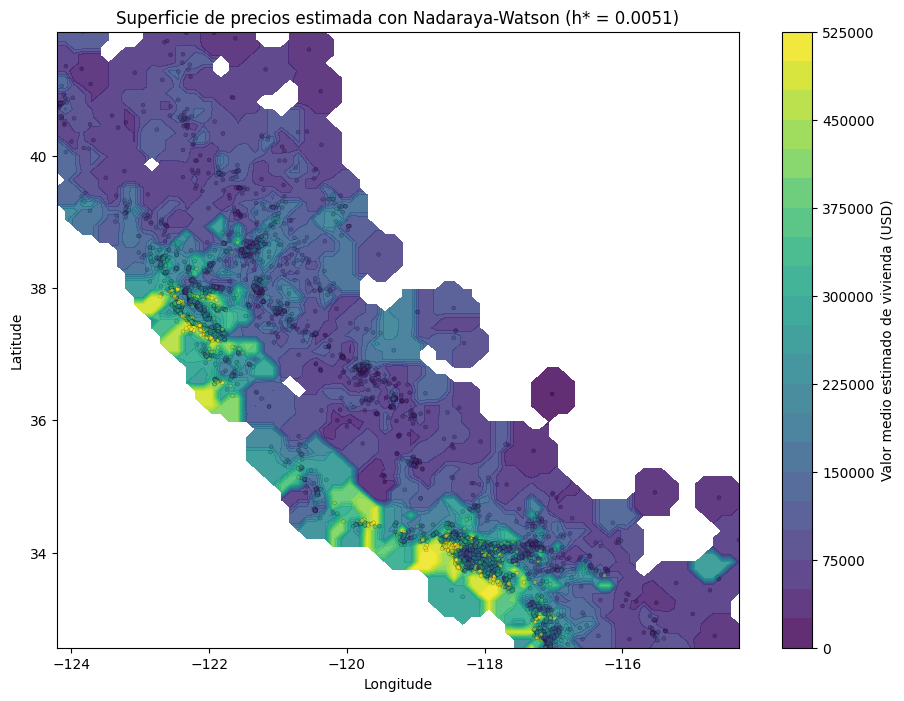

In [ ]:
# 5.5 Gráfico de contornos rellenos con los datos reales superpuestos
plt.figure(figsize=(11, 8))

# Superficie estimada por Nadaraya-Watson
contorno = plt.contourf(XX1_orig, XX2_orig, ZZ, levels=20, cmap='viridis', alpha=0.85)
plt.colorbar(contorno, label='Valor medio estimado de vivienda (USD)')

# Datos reales superpuestos
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap='viridis',
            s=8, edgecolors='black', linewidths=0.2, alpha=0.6)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'Superficie de precios estimada con Nadaraya-Watson (h* = {h_opt:.4f})')
plt.show()

#### Conclusión del Punto 5

- Existe una clara concordancia entre la dispersión original y el diagrama de contorno: las regiones con colores asociados a precios altos y bajos se mantienen consistentes en ambas representaciones, lo que evidencia que el modelo preserva la estructura espacial de los datos.
- La superficie estimada es suave y coherente con la realidad inmobiliaria: las viviendas tienden a ser más costosas en zonas con alta concentración urbana y con cercanía a la costa; en cambio, zonas menos densas e interiores suelen presentar precios más bajos.
- ⁠Aunque el modelo no incorpora variables adicionales como ingresos, antigüedad de la vivienda, número de habitaciones o cercanía a servicios, con la ubicación por sí sola, es capaz de recuperar una estructura espacial del mercado.